# Кластеризація даних
**Бізнес-контекст:** компанія ClientScope аналізує транзакції клієнтів, щоб виділяти групи зі схожими витратами й активністю. Потрібно застосувати алгоритми кластеризації для сегментації клієнтів за поведінкою.

**Два алгоритми:**
- **K-Means** ділить дані рівно на задану кількість кластерів: обирає центри, відносить кожну точку до найближчого центру й уточнює центри, доки розбиття не стабілізується.
- **DBSCAN** шукає щільні області: точка належить кластеру, якщо поруч (у радіусі `eps`) є щонайменше `min_samples` сусідів. Кількість кластерів визначається автоматично, а розріджені точки позначаються як шум (мітка `-1`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans, DBSCAN

## Завдання 1. Підготовка даних

In [2]:
X, _ = make_blobs(n_samples=600, centers=5, cluster_std=1.2, random_state=0)
df = pd.DataFrame(X, columns=["income", "spending_score"])
print(df.shape)
df.head()

(600, 2)


,income,spending_score
0,8.786125,-1.461927
1,-3.260832,1.465231
2,1.336883,-0.441413
3,-4.363913,2.942283
4,9.339461,-1.972397


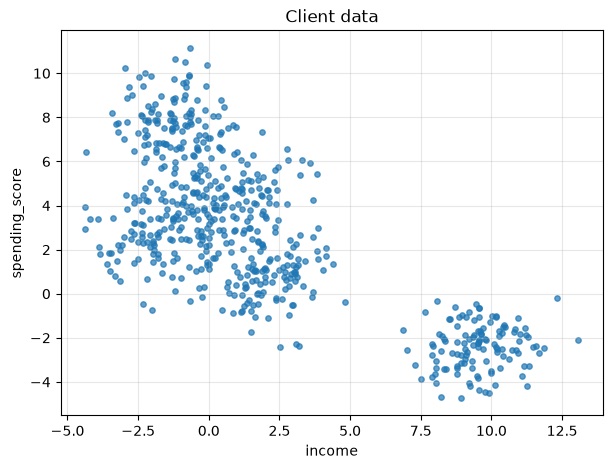

In [3]:
plt.figure(figsize=(7, 5))
plt.scatter(df["income"], df["spending_score"], s=15, alpha=0.7)
plt.xlabel("income")
plt.ylabel("spending_score")
plt.title("Client data")
plt.grid(alpha=0.3)
plt.show()

## Завдання 2. Алгоритм K-Means


In [4]:
kmeans = KMeans(n_clusters=5, random_state=0, n_init=10)
df["segment"] = kmeans.fit_predict(df[["income", "spending_score"]])
print(df["segment"].value_counts().sort_index())

segment
0    119
1    121
2    120
3    120
4    120
Name: count, dtype: int64


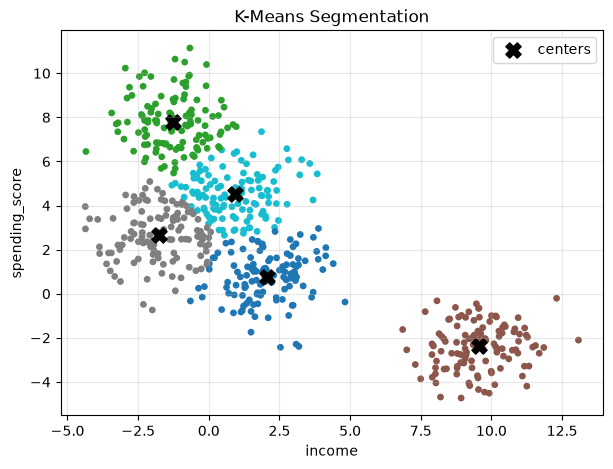

In [5]:
plt.figure(figsize=(7, 5))
plt.scatter(df["income"], df["spending_score"], c=df["segment"], cmap="tab10", s=15)
plt.scatter(*kmeans.cluster_centers_.T, c="black", marker="X", s=120, label="centers")
plt.xlabel("income")
plt.ylabel("spending_score")
plt.title("K-Means Segmentation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Завдання 3. Алгоритм DBSCAN


In [6]:
dbscan = DBSCAN(eps=1.5, min_samples=10)
df["cluster_dbscan"] = dbscan.fit_predict(df[["income", "spending_score"]])

n_clusters = len(set(df["cluster_dbscan"])) - (1 if -1 in set(df["cluster_dbscan"]) else 0)
n_noise = int((df["cluster_dbscan"] == -1).sum())
print("Знайдено кластерів:", n_clusters)
print("Точок-шуму (-1):", n_noise)
print(df["cluster_dbscan"].value_counts().sort_index())

Знайдено кластерів: 2
Точок-шуму (-1): 1
cluster_dbscan
-1      1
 0    119
 1    480
Name: count, dtype: int64


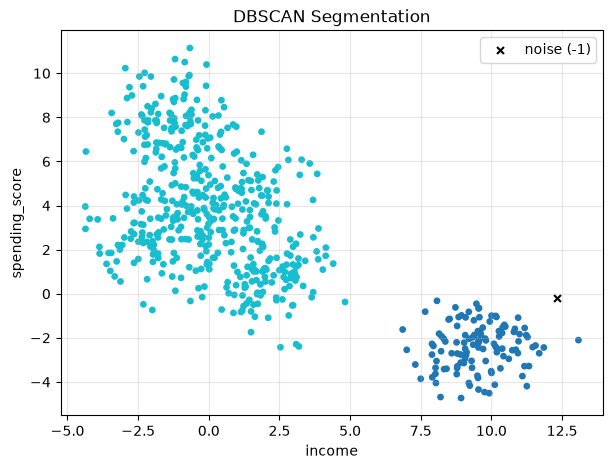

In [7]:
plt.figure(figsize=(7, 5))
noise = df["cluster_dbscan"] == -1
plt.scatter(df.loc[~noise, "income"], df.loc[~noise, "spending_score"],
            c=df.loc[~noise, "cluster_dbscan"], cmap="tab10", s=15)
plt.scatter(df.loc[noise, "income"], df.loc[noise, "spending_score"],
            c="black", marker="x", s=25, label="noise (-1)")
plt.xlabel("income")
plt.ylabel("spending_score")
plt.title("DBSCAN Segmentation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()